# Bài tập 2 — Cài đặt và đánh giá Logistic Regression

**Môn học:** Nhận dạng mẫu — **Giảng viên:** TS. Nguyễn Xuân Đức
**Học viên:** Trần Vũ Trường — **Mã học viên:** B26CHKH096 — **Lớp:** M26CQKH02-B

**Dữ liệu:** Rice (Cammeo and Osmancik), UCI Machine Learning Repository, id 545.

Notebook gồm 5 phần theo đúng yêu cầu của đề (mục 1–5) và phần mở rộng (mục 6).
Chạy từ đầu đến cuối bằng *Restart & Run All*; dữ liệu nằm sẵn trong `data/`.

In [1]:
import json, sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from scipy.io import arff
from scipy.stats import binomtest
from sklearn.calibration import calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, brier_score_loss, confusion_matrix,
                             f1_score, log_loss, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from logreg_numpy import (LogisticRegressionGD, LogisticRegressionNewton, gradient,
                          lam_from_C, lipschitz_constant, log_loss_from_score,
                          objective, score, sigmoid)

SEED = 96
FIG = ROOT / "outputs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
RESULTS = {}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False})
C_NP, C_SK, C_BASE = "#2a78d6", "#eb6834", "#888888"
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / name, bbox_inches="tight")
    plt.show()

numpy 2.5.3 | pandas 3.0.6 | scikit-learn 1.9.1


## 1. Chuẩn bị dữ liệu

Mỗi dòng là một hạt gạo được chụp ảnh; 7 đặc trưng hình thái được trích từ ảnh
(đơn vị pixel). Nhãn là giống gạo: **Cammeo** hoặc **Osmancik**.

| Đặc trưng | Ý nghĩa |
|---|---|
| `Area` | Số pixel bên trong đường biên hạt gạo |
| `Perimeter` | Chu vi: tổng khoảng cách giữa các pixel trên đường biên |
| `Major_Axis_Length` | Độ dài trục chính (đoạn dài nhất vẽ được trên hạt) |
| `Minor_Axis_Length` | Độ dài trục phụ (đoạn ngắn nhất) |
| `Eccentricity` | Độ lệch tâm của elip có cùng moment với hạt (0 = tròn, gần 1 = dẹt dài) |
| `Convex_Area` | Số pixel của bao lồi nhỏ nhất chứa hạt |
| `Extent` | Tỷ lệ diện tích hạt trên diện tích hình chữ nhật bao quanh |

Quy ước nhãn: **y = 1 là Cammeo** (lớp dương), y = 0 là Osmancik. Precision, recall
và F1 bên dưới đều tính cho lớp Cammeo.

In [2]:
raw, _ = arff.loadarff(ROOT / "data" / "Rice_Cammeo_Osmancik.arff")
df = pd.DataFrame(raw)
df["Class"] = df["Class"].str.decode("utf-8")
FEATURES = [c for c in df.columns if c != "Class"]
X_all = df[FEATURES].to_numpy(float)
y_all = (df["Class"] == "Cammeo").to_numpy(int)

print("Kích thước:", df.shape, "| thiếu dữ liệu:", int(df.isna().sum().sum()),
      "| dòng trùng:", int(df.duplicated().sum()))
ratio = df["Class"].value_counts().to_frame("Số mẫu")
ratio["Tỷ lệ (%)"] = 100 * ratio["Số mẫu"] / len(df)
display(ratio)
display(df[FEATURES].describe().T[["mean", "std", "min", "max"]])

Kích thước: (3810, 8) | thiếu dữ liệu: 0 | dòng trùng: 0


,Số mẫu,Tỷ lệ (%)
Class,,
Osmancik,2180,57.2178
Cammeo,1630,42.7822


,mean,std,min,max
Area,12667.7276,1732.3677,7551.0000,18913.0000
Perimeter,454.2392,35.5971,359.1000,548.4460
Major_Axis_Length,188.7762,17.4487,145.2645,239.0105
Minor_Axis_Length,86.3138,5.7298,59.5324,107.5424
Eccentricity,0.8869,0.0208,0.7772,0.9480
Convex_Area,12952.4969,1776.9720,7723.0000,19099.0000
Extent,0.6619,0.0772,0.4974,0.8610


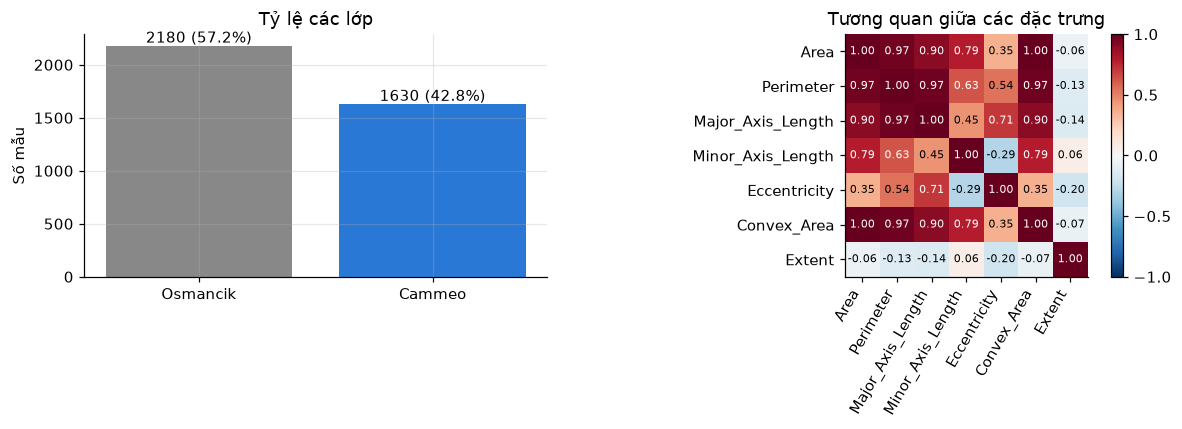

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(ratio.index, ratio["Số mẫu"], color=[C_BASE, C_NP])
for i, (n, pct) in enumerate(zip(ratio["Số mẫu"], ratio["Tỷ lệ (%)"])):
    axes[0].text(i, n + 30, f"{n} ({pct:.1f}%)", ha="center")
axes[0].set_title("Tỷ lệ các lớp"); axes[0].set_ylabel("Số mẫu")
corr = df[FEATURES].corr().to_numpy()
im = axes[1].imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
axes[1].set_xticks(range(7), FEATURES, rotation=60, ha="right")
axes[1].set_yticks(range(7), FEATURES); axes[1].grid(False)
for i in range(7):
    for j in range(7):
        axes[1].text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center", fontsize=7,
                     color="white" if abs(corr[i, j]) > 0.6 else "black")
axes[1].set_title("Tương quan giữa các đặc trưng"); fig.colorbar(im, ax=axes[1], fraction=0.046)
savefig("01_lop_va_tuong_quan.png")

### Chia dữ liệu và chuẩn hoá

Chia phân tầng theo nhãn thành Train 60% / Validation 20% / Test 20%. Train dùng để
ước lượng tham số, Validation để chọn ngưỡng, Test chỉ dùng cho báo cáo cuối.
`StandardScaler` học μ, σ **chỉ trên Train** rồi áp dụng cho Validation và Test:
z = (x − μ) / σ.

In [4]:
X_dev, X_test_raw, y_dev, y_test = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=SEED)
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=SEED)

scaler = StandardScaler().fit(X_train_raw)
X_train, X_val, X_test = (scaler.transform(a) for a in (X_train_raw, X_val_raw, X_test_raw))
n_train = len(y_train)
split = pd.DataFrame({"Số mẫu": [len(y_train), len(y_val), len(y_test)],
                      "Tỷ lệ Cammeo (%)": [100 * y_train.mean(), 100 * y_val.mean(), 100 * y_test.mean()]},
                     index=["Train", "Validation", "Test"])
display(split)
RESULTS["data"] = {"n": len(df), "n_features": len(FEATURES),
                   "n_cammeo": int(y_all.sum()), "n_osmancik": int((1 - y_all).sum()),
                   "n_train": len(y_train), "n_val": len(y_val), "n_test": len(y_test)}

,Số mẫu,Tỷ lệ Cammeo (%)
Train,2286,42.7822
Validation,762,42.7822
Test,762,42.7822


## 2. Cài đặt bằng NumPy

Mã nguồn nằm trong `src/logreg_numpy.py`, chỉ dùng phép toán mảng của NumPy:

- score: $s = \mathbf{w}^\top \mathbf{x} + b$
- sigmoid: $p = \dfrac{1}{1 + e^{-s}}$
- log loss: $L = \dfrac{1}{n}\sum_i -\big[y_i \ln p_i + (1-y_i)\ln(1-p_i)\big]$
- hàm mục tiêu có L2: $J = L + \lambda \sum_j w_j^2$ (không phạt $b$)
- gradient: $\nabla_{\mathbf{w}} J = \dfrac{X^\top(\mathbf{p}-\mathbf{y})}{n} + 2\lambda\mathbf{w}$, $\quad \dfrac{\partial J}{\partial b} = \text{mean}(\mathbf{p}-\mathbf{y})$
- cập nhật: $\mathbf{w} \leftarrow \mathbf{w} - \eta\,\nabla_{\mathbf{w}} J$, $\quad b \leftarrow b - \eta\,\dfrac{\partial J}{\partial b}$

### 2.1. Kiểm thử cài đặt

(a) Tái lập ví dụ tính tay trong slide: $\mathbf{x} = (1; 2)$, $\mathbf{w} = (0{,}8; -0{,}3)$,
$b = -1$, $y = 1$, $\eta = 0{,}1$. Slide cho $s = -0{,}8$, $p \approx 0{,}310$, $\ell \approx 1{,}17$;
sau một bước: $w_1 = 0{,}869$, $w_2 = -0{,}162$, $b = -0{,}931$, $p \approx 0{,}405$, $\ell \approx 0{,}90$.

In [5]:
x_s, y_s = np.array([[1.0, 2.0]]), np.array([1.0])
w_s, b_s, eta_s = np.array([0.8, -0.3]), -1.0, 0.1
s0 = score(x_s, w_s, b_s); p0 = sigmoid(s0); l0 = log_loss_from_score(s0, y_s)
gw, gb = gradient(x_s, y_s, w_s, b_s)
w1, b1 = w_s - eta_s * gw, b_s - eta_s * gb
s1 = score(x_s, w1, b1); p1 = sigmoid(s1); l1 = log_loss_from_score(s1, y_s)
print(f"Trước: s = {s0[0]:.3f}, p = {p0[0]:.3f}, loss = {l0:.3f}")
print(f"Gradient: dw = ({gw[0]:.3f}; {gw[1]:.3f}), db = {gb:.3f}")
print(f"Sau 1 bước: w = ({w1[0]:.3f}; {w1[1]:.3f}), b = {b1:.3f}, p = {p1[0]:.3f}, loss = {l1:.3f}")
assert np.allclose([s0[0], p0[0], l0], [-0.8, 0.310, 1.17], atol=5e-3)
assert np.allclose([w1[0], w1[1], b1, p1[0], l1], [0.869, -0.162, -0.931, 0.405, 0.90], atol=5e-3)
print("Khớp với ví dụ trong slide.")

Trước: s = -0.800, p = 0.310, loss = 1.171
Gradient: dw = (-0.690; -1.380), db = -0.690
Sau 1 bước: w = (0.869; -0.162), b = -0.931, p = 0.405, loss = 0.905
Khớp với ví dụ trong slide.


(b) Kiểm tra gradient bằng sai phân hữu hạn trung tâm tại một điểm ngẫu nhiên.

In [6]:
C = 1.0                              # cùng giá trị mặc định của sklearn
lam = lam_from_C(C, n_train)
rng = np.random.default_rng(SEED)
w_r, b_r, eps = rng.normal(size=X_train.shape[1]), 0.3, 1e-6
gw, gb = gradient(X_train, y_train, w_r, b_r, lam)
num = np.zeros_like(w_r)
for j in range(len(w_r)):
    e = np.zeros_like(w_r); e[j] = eps
    num[j] = (objective(X_train, y_train, w_r + e, b_r, lam)
              - objective(X_train, y_train, w_r - e, b_r, lam)) / (2 * eps)
num_b = (objective(X_train, y_train, w_r, b_r + eps, lam)
         - objective(X_train, y_train, w_r, b_r - eps, lam)) / (2 * eps)
g_a, g_n = np.r_[gw, gb], np.r_[num, num_b]
rel_err = np.linalg.norm(g_a - g_n) / (np.linalg.norm(g_a) + np.linalg.norm(g_n))
print(f"Sai số tương đối giữa gradient giải tích và sai phân: {rel_err:.2e}")
assert rel_err < 1e-7
RESULTS["grad_check_rel_err"] = float(rel_err)

Sai số tương đối giữa gradient giải tích và sai phân: 7.93e-11


### 2.2. Learning rate, điều kiện dừng và huấn luyện

- **Regularization:** để hai bản tối ưu *cùng một hàm mục tiêu*, bản NumPy dùng L2 với
  $\lambda = \dfrac{1}{2Cn}$, $C = 1$ (mặc định của sklearn). sklearn tối thiểu hoá
  $\tfrac12\lVert\mathbf{w}\rVert^2 + C\sum_i \ell_i$; chia cho $Cn$ được đúng $J$ ở trên.
  $C$ điều khiển regularization, không phải bước học.
- **Learning rate:** $\eta = 1/L_{\max}$, với $L_{\max} = \lambda_{\max}(\tilde X^\top \tilde X)/(4n) + 2\lambda$
  là cận trên độ cong của $J$ ($\tilde X$ là $X$ thêm cột 1; $p(1-p) \le 1/4$). Với bước này
  gradient descent chắc chắn làm $J$ giảm ở mọi vòng lặp.
- **Khởi tạo:** $\mathbf{w} = \mathbf{0}$, $b = 0$.
- **Điều kiện dừng:** $\lVert\nabla J\rVert_2 < 10^{-6}$, hoặc tối đa 200.000 vòng lặp.

In [7]:
L_max = lipschitz_constant(X_train, lam)
eta = 1.0 / L_max
TOL, MAX_ITER = 1e-6, 200_000
t0 = time.perf_counter()
gd = LogisticRegressionGD(eta=eta, lam=lam, max_iter=MAX_ITER, tol=TOL).fit(X_train, y_train)
t_gd = time.perf_counter() - t0
print(f"C = {C}, lambda = {lam:.3e}, L_max = {L_max:.4f}, eta = 1/L_max = {eta:.4f}")
print(f"Dừng sau {gd.n_iter_} vòng lặp ({t_gd:.1f} s); hội tụ theo điều kiện dừng: {gd.converged_}")
print(f"Log loss train: {gd.loss_history_[0]:.4f} -> {gd.loss_history_[-1]:.6f};"
      f" ||grad J|| cuối: {gd.grad_norm_history_[-1]:.2e}")
loss_hist = np.array(gd.loss_history_)
for k in (10, 100, 1000):
    print(f"  sau {k:>5} vòng: log loss = {loss_hist[k]:.6f}")
RESULTS["numpy_gd"] = {"C": C, "lambda": lam, "L_max": L_max, "eta": eta, "tol": TOL,
                       "max_iter": MAX_ITER, "n_iter": int(gd.n_iter_),
                       "converged": bool(gd.converged_), "seconds": t_gd,
                       "train_log_loss": float(loss_hist[-1]),
                       "loss_at": {str(k): float(loss_hist[k]) for k in (10, 100, 1000)}}

C = 1.0, lambda = 2.187e-04, L_max = 1.1459, eta = 1/L_max = 0.8726
Dừng sau 15476 vòng lặp (5.8 s); hội tụ theo điều kiện dừng: True
Log loss train: 0.6931 -> 0.193608; ||grad J|| cuối: 1.00e-06
  sau    10 vòng: log loss = 0.215509
  sau   100 vòng: log loss = 0.194637
  sau  1000 vòng: log loss = 0.194211


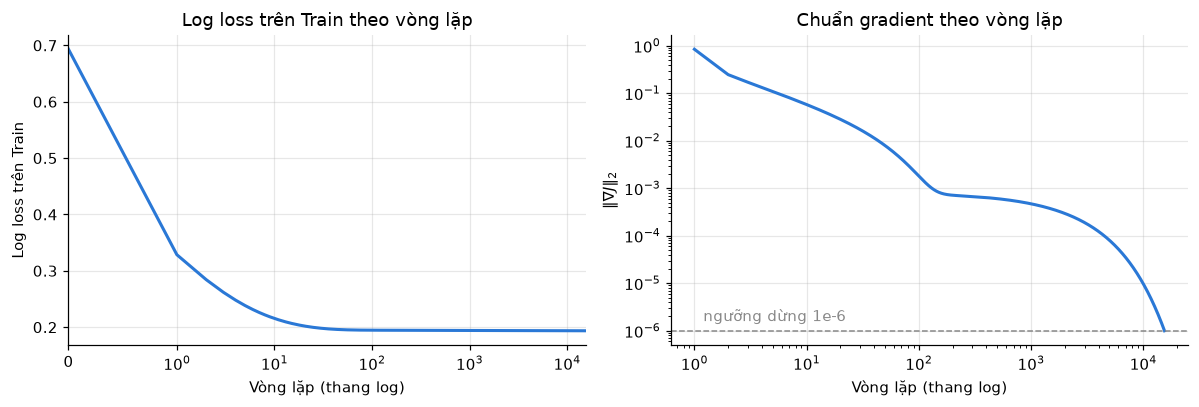

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
it = np.arange(len(loss_hist))
axes[0].plot(it, loss_hist, color=C_NP, lw=2)
axes[0].set_xscale("symlog", linthresh=1); axes[0].set_xlim(0, len(loss_hist))
axes[0].set_xlabel("Vòng lặp (thang log)"); axes[0].set_ylabel("Log loss trên Train")
axes[0].set_title("Log loss trên Train theo vòng lặp")
axes[1].semilogy(np.arange(1, len(gd.grad_norm_history_) + 1), gd.grad_norm_history_, color=C_NP, lw=2)
axes[1].axhline(TOL, color=C_BASE, ls="--", lw=1); axes[1].text(1.2, TOL * 1.6, "ngưỡng dừng 1e-6", color=C_BASE)
axes[1].set_xscale("log"); axes[1].set_xlabel("Vòng lặp (thang log)")
axes[1].set_ylabel(r"$\|\nabla J\|_2$"); axes[1].set_title("Chuẩn gradient theo vòng lặp")
savefig("02_log_loss_train.png")

### 2.3. Ảnh hưởng của learning rate

Chạy 300 vòng với vài giá trị $\eta$ để thấy các dạng đường loss: giảm chậm, giảm đều,
dao động và phân kỳ.

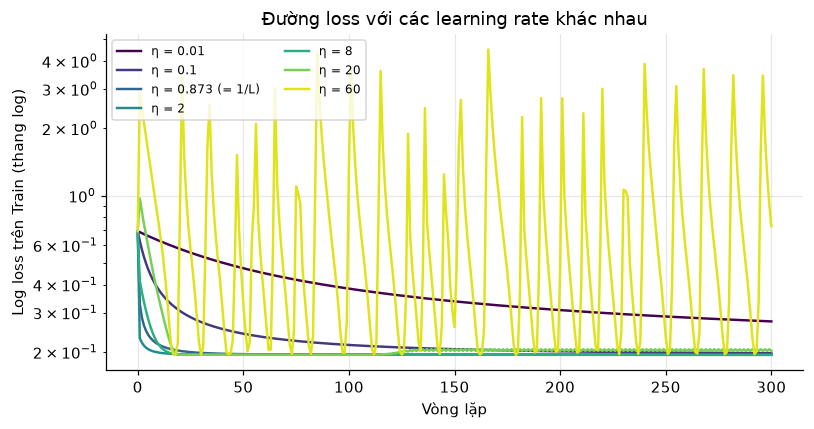

,eta,log loss sau 300 vòng,số vòng loss tăng
0,0.0100,0.2739,0
1,0.1000,0.1975,0
2,0.8726,0.1945,0
3,2.0000,0.1943,0
4,8.0000,0.1939,0
5,20.0000,0.2021,115
6,60.0000,0.7288,80


In [9]:
etas = [0.01, 0.1, eta, 2.0, 8.0, 20.0, 60.0]
fig, ax = plt.subplots(figsize=(7.5, 4))
lr_rows = []
for e_, col in zip(etas, plt.cm.viridis(np.linspace(0, 0.95, len(etas)))):
    m = LogisticRegressionGD(eta=e_, lam=lam, max_iter=300, tol=0.0).fit(X_train, y_train)
    h = np.array(m.loss_history_)
    n_up = int(np.sum(np.diff(h) > 1e-12))
    lr_rows.append({"eta": e_, "log loss sau 300 vòng": h[-1], "số vòng loss tăng": n_up})
    ax.plot(h, color=col, lw=1.6, label=f"η = {e_:.3g}" + (" (= 1/L)" if e_ == eta else ""))
ax.set_yscale("log"); ax.set_xlabel("Vòng lặp"); ax.set_ylabel("Log loss trên Train (thang log)")
ax.set_title("Đường loss với các learning rate khác nhau"); ax.legend(fontsize=8, ncol=2)
savefig("03_learning_rate.png")
lr_table = pd.DataFrame(lr_rows); display(lr_table)
RESULTS["lr_sweep"] = lr_rows

## 3. Scikit-learn

Huấn luyện `LogisticRegression` trên **cùng** `X_train` đã chuẩn hoá, cùng $C = 1$ và
phạt L2. Đặt `tol=1e-10` để bộ giải lbfgs chạy tới nghiệm chính xác, nhờ đó chênh lệch
còn lại (nếu có) là do thuật toán tối ưu chứ không do dừng sớm.

In [10]:
sk = LogisticRegression(C=C, tol=1e-10, max_iter=10_000).fit(X_train, y_train)
w_sk, b_sk = sk.coef_[0], float(sk.intercept_[0])
J_np = objective(X_train, y_train, gd.w_, gd.b_, lam)
J_sk = objective(X_train, y_train, w_sk, b_sk, lam)
p_np_test, p_sk_test = gd.predict_proba(X_test), sk.predict_proba(X_test)[:, 1]
print(f"sklearn (lbfgs) dừng sau {int(sk.n_iter_[0])} vòng lặp")
print(f"Hàm mục tiêu J trên Train: NumPy = {J_np:.10f} | sklearn = {J_sk:.10f} | chênh = {J_np - J_sk:.2e}")
print(f"max |w_numpy - w_sklearn| = {np.max(np.abs(gd.w_ - w_sk)):.2e}; |b_numpy - b_sklearn| = {abs(gd.b_ - b_sk):.2e}")
print(f"max |p_numpy - p_sklearn| trên Test = {np.max(np.abs(p_np_test - p_sk_test)):.2e}")
coef = pd.DataFrame({"NumPy": np.r_[gd.w_, gd.b_], "sklearn": np.r_[w_sk, b_sk]},
                    index=FEATURES + ["bias b"])
coef["chênh lệch"] = coef["NumPy"] - coef["sklearn"]
display(coef.style.format("{:.6f}"))
RESULTS["equivalence"] = {"sk_n_iter": int(sk.n_iter_[0]), "J_numpy": J_np, "J_sklearn": J_sk,
                          "max_dw": float(np.max(np.abs(gd.w_ - w_sk))),
                          "db": float(abs(gd.b_ - b_sk)),
                          "max_dp_test": float(np.max(np.abs(p_np_test - p_sk_test)))}
RESULTS["coef"] = {"features": FEATURES, "w_numpy": gd.w_.tolist(), "b_numpy": gd.b_,
                   "w_sklearn": w_sk.tolist(), "b_sklearn": b_sk}

sklearn (lbfgs) dừng sau 43 vòng lặp
Hàm mục tiêu J trên Train: NumPy = 0.1952433649 | sklearn = 0.1952433639 | chênh = 1.05e-09
max |w_numpy - w_sklearn| = 1.74e-03; |b_numpy - b_sklearn| = 1.92e-05
max |p_numpy - p_sklearn| trên Test = 3.02e-05


,NumPy,sklearn,chênh lệch
Area,0.478278,0.477203,0.001075
Perimeter,0.436460,0.436017,0.000443
Major_Axis_Length,0.937057,0.937019,0.000038
Minor_Axis_Length,-0.257752,-0.257997,0.000245
Eccentricity,1.412588,1.412545,0.000043
Convex_Area,2.028721,2.030460,-0.001739
Extent,0.045565,0.045558,0.000007
bias b,-0.772030,-0.772011,-0.000019


## 4. Đánh giá trên tập Test

Ngưỡng quyết định $\tau = 0{,}5$. ROC-AUC và log loss tính **từ xác suất dự đoán**;
accuracy, precision, recall, F1 tính từ nhãn dự đoán. Dòng baseline là
`DummyClassifier(strategy="prior")`: luôn dự đoán theo tỷ lệ lớp của Train.

In [11]:
def evaluate(y_true, p, tau=0.5):
    y_hat = (p >= tau).astype(int)
    return {"Accuracy": accuracy_score(y_true, y_hat),
            "Precision": precision_score(y_true, y_hat, zero_division=0),
            "Recall": recall_score(y_true, y_hat),
            "F1": f1_score(y_true, y_hat, zero_division=0),
            "ROC-AUC": roc_auc_score(y_true, p),
            "Log loss": log_loss(y_true, p, labels=[0, 1])}

dummy = DummyClassifier(strategy="prior").fit(X_train, y_train)
p_dummy_test = dummy.predict_proba(X_test)[:, 1]
table = pd.DataFrame({"Baseline (prior)": evaluate(y_test, p_dummy_test),
                      "NumPy (gradient descent)": evaluate(y_test, p_np_test),
                      "sklearn LogisticRegression": evaluate(y_test, p_sk_test)}).T
display(table)
RESULTS["test_metrics"] = table.to_dict(orient="index")

,Accuracy,Precision,Recall,F1,ROC-AUC,Log loss
Baseline (prior),0.5722,0.0000,0.0000,0.0000,0.5000,0.6827
NumPy (gradient descent),0.9239,0.8964,0.9294,0.9127,0.9814,0.1767
sklearn LogisticRegression,0.9239,0.8964,0.9294,0.9127,0.9814,0.1767


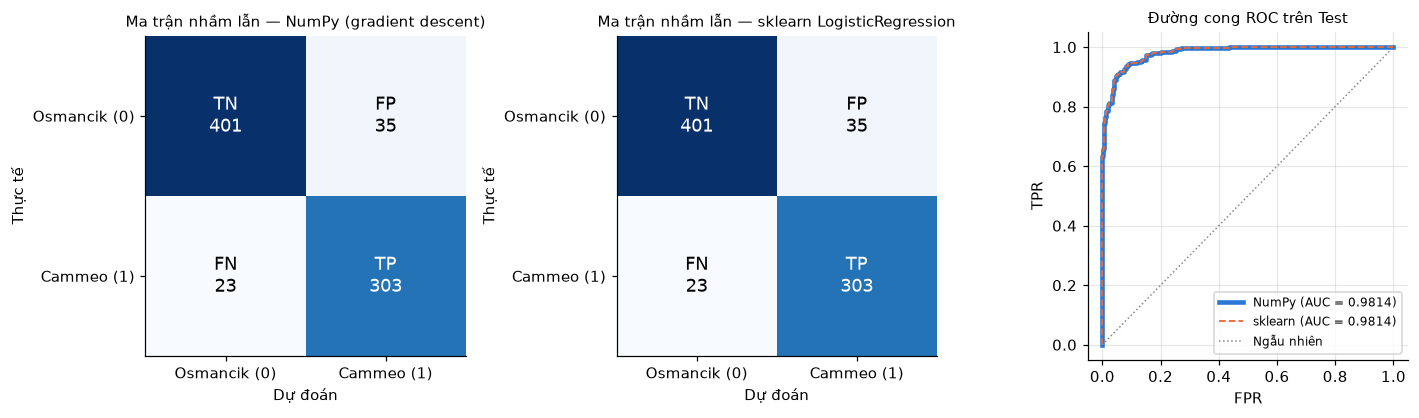

Ma trận nhầm lẫn NumPy  [[TN, FP], [FN, TP]]: [[401, 35], [23, 303]]
Ma trận nhầm lẫn sklearn [[TN, FP], [FN, TP]]: [[401, 35], [23, 303]]
Số mẫu Test mà hai bản dự đoán khác nhau: 0


In [12]:
yhat_np, yhat_sk = (p_np_test >= 0.5).astype(int), (p_sk_test >= 0.5).astype(int)
cm_np = confusion_matrix(y_test, yhat_np, labels=[0, 1])
cm_sk = confusion_matrix(y_test, yhat_sk, labels=[0, 1])
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
for ax, cm, title in zip(axes[:2], (cm_np, cm_sk), ("NumPy (gradient descent)", "sklearn LogisticRegression")):
    ax.imshow(cm, cmap="Blues"); ax.grid(False)
    names = [["TN", "FP"], ["FN", "TP"]]
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{names[i][j]}\n{cm[i, j]}", ha="center", va="center", fontsize=12,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["Osmancik (0)", "Cammeo (1)"]); ax.set_yticks([0, 1], ["Osmancik (0)", "Cammeo (1)"])
    ax.set_xlabel("Dự đoán"); ax.set_ylabel("Thực tế"); ax.set_title(f"Ma trận nhầm lẫn — {title}", fontsize=10)
fpr_n, tpr_n, _ = roc_curve(y_test, p_np_test); fpr_s, tpr_s, _ = roc_curve(y_test, p_sk_test)
axes[2].plot(fpr_n, tpr_n, color=C_NP, lw=3, label=f"NumPy (AUC = {roc_auc_score(y_test, p_np_test):.4f})")
axes[2].plot(fpr_s, tpr_s, color=C_SK, lw=1.2, ls="--", label=f"sklearn (AUC = {roc_auc_score(y_test, p_sk_test):.4f})")
axes[2].plot([0, 1], [0, 1], color=C_BASE, lw=1, ls=":", label="Ngẫu nhiên")
axes[2].set_xlabel("FPR"); axes[2].set_ylabel("TPR"); axes[2].set_title("Đường cong ROC trên Test", fontsize=10)
axes[2].legend(fontsize=8)
savefig("04_confusion_roc.png")
print("Ma trận nhầm lẫn NumPy  [[TN, FP], [FN, TP]]:", cm_np.tolist())
print("Ma trận nhầm lẫn sklearn [[TN, FP], [FN, TP]]:", cm_sk.tolist())
print("Số mẫu Test mà hai bản dự đoán khác nhau:", int(np.sum(yhat_np != yhat_sk)))
RESULTS["confusion"] = {"numpy": cm_np.tolist(), "sklearn": cm_sk.tolist(),
                        "n_disagree": int(np.sum(yhat_np != yhat_sk))}

### Lỗi phân loại thường gặp

Xem các mẫu Test bị phân loại sai của bản NumPy: xác suất dự đoán nằm ở đâu so với
ngưỡng, và các mẫu sai khác gì với mẫu đúng cùng lớp.

Số mẫu sai: 58/762 (FP = 35, FN = 23)
Mẫu sai có p trong (0,3; 0,7): 27 (47%); mẫu sai 'tự tin' (p < 0,1 hoặc p > 0,9): 7


,số mẫu,Area,Major_Axis_Length,Minor_Axis_Length,Eccentricity,p
nhóm,,,,,,
TN,401,11470.0424,175.0229,84.5197,0.8744,0.0602
FP,35,13120.0571,195.2434,86.6273,0.8955,0.6985
FN,23,12083.6087,186.6448,83.7714,0.8932,0.2677
TP,303,14429.5380,207.6568,89.5043,0.9016,0.9306


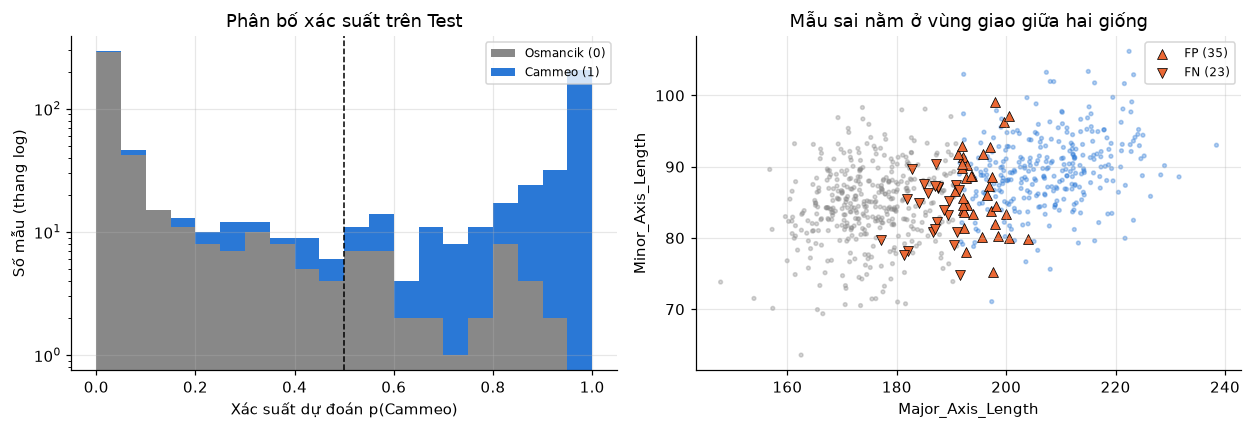

In [13]:
err = pd.DataFrame(X_test_raw, columns=FEATURES)
err["y"], err["p"], err["y_hat"] = y_test, p_np_test, yhat_np
err["nhóm"] = np.select([(err.y == 1) & (err.y_hat == 1), (err.y == 0) & (err.y_hat == 0),
                         (err.y == 0) & (err.y_hat == 1)], ["TP", "TN", "FP"], default="FN")
wrong = err[err.y != err.y_hat]
near = wrong[(wrong.p > 0.3) & (wrong.p < 0.7)]
print(f"Số mẫu sai: {len(wrong)}/{len(err)} (FP = {(wrong['nhóm'] == 'FP').sum()}, FN = {(wrong['nhóm'] == 'FN').sum()})")
print(f"Mẫu sai có p trong (0,3; 0,7): {len(near)} ({100 * len(near) / len(wrong):.0f}%);"
      f" mẫu sai 'tự tin' (p < 0,1 hoặc p > 0,9): {int(((wrong.p < 0.1) | (wrong.p > 0.9)).sum())}")
grp = err.groupby("nhóm")[["Area", "Major_Axis_Length", "Minor_Axis_Length", "Eccentricity", "p"]].mean()
grp.insert(0, "số mẫu", err["nhóm"].value_counts())
grp = grp.loc[["TN", "FP", "FN", "TP"]]
display(grp)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
bins = np.linspace(0, 1, 21)
axes[0].hist([err.p[err.y == 0], err.p[err.y == 1]], bins=bins, stacked=True,
             color=[C_BASE, C_NP], label=["Osmancik (0)", "Cammeo (1)"])
axes[0].axvline(0.5, color="k", ls="--", lw=1); axes[0].set_yscale("log")
axes[0].set_xlabel("Xác suất dự đoán p(Cammeo)"); axes[0].set_ylabel("Số mẫu (thang log)")
axes[0].set_title("Phân bố xác suất trên Test"); axes[0].legend(fontsize=8)
ok = err[err.y == err.y_hat]
axes[1].scatter(ok.Major_Axis_Length, ok.Minor_Axis_Length, s=6, c=np.where(ok.y == 1, C_NP, C_BASE), alpha=0.35)
for g, mk in (("FP", "^"), ("FN", "v")):
    w_ = wrong[wrong["nhóm"] == g]
    axes[1].scatter(w_.Major_Axis_Length, w_.Minor_Axis_Length, s=42, marker=mk, c=C_SK,
                    edgecolors="k", linewidths=0.5, label=f"{g} ({len(w_)})")
axes[1].set_xlabel("Major_Axis_Length"); axes[1].set_ylabel("Minor_Axis_Length")
axes[1].set_title("Mẫu sai nằm ở vùng giao giữa hai giống"); axes[1].legend(fontsize=8)
savefig("05_loi_phan_loai.png")
RESULTS["errors"] = {"n_wrong": len(wrong), "n_test": len(err),
                     "fp": int((wrong["nhóm"] == "FP").sum()), "fn": int((wrong["nhóm"] == "FN").sum()),
                     "near_threshold": len(near),
                     "confident_wrong": int(((wrong.p < 0.1) | (wrong.p > 0.9)).sum()),
                     "group_means": grp.to_dict(orient="index")}

Các mẫu sai "tự tin" nhất, kèm đóng góp $w_j z_j$ của từng đặc trưng vào score
(z là giá trị đã chuẩn hoá): cho biết đặc trưng nào kéo dự đoán về phía sai.

In [14]:
contrib = pd.DataFrame(X_test * gd.w_, columns=FEATURES)
worst = wrong.assign(do_tu_tin=(wrong.p - 0.5).abs()).sort_values("do_tu_tin", ascending=False).head(6)
show = contrib.loc[worst.index].copy()
show.insert(0, "p", worst.p); show.insert(0, "nhóm", worst["nhóm"])
show["score s"] = show[FEATURES].sum(axis=1) + gd.b_
display(show.style.format({c: "{:.2f}" for c in FEATURES + ["score s"]} | {"p": "{:.3f}"}))

,nhóm,p,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,score s
36,FN,0.026,-0.47,-0.36,-0.61,0.29,0.42,-2.08,-0.04,-3.62
453,FP,0.947,0.00,0.25,0.83,0.28,2.27,0.02,0.01,2.89
160,FP,0.930,0.68,0.47,0.64,-0.48,-0.80,2.83,0.04,2.59
268,FN,0.078,-0.17,-0.15,-0.36,0.04,-0.28,-0.74,-0.04,-2.47
488,FN,0.085,-0.47,-0.26,-0.35,0.36,1.10,-1.92,-0.07,-2.37
648,FN,0.086,-0.51,-0.19,-0.39,0.39,1.14,-1.96,-0.06,-2.37


## 5. Nhận xét

**Sự hội tụ.** Với $\eta = 1/L_{\max} \approx 0{,}873$, log loss trên Train giảm đơn điệu từ
0,6931 xuống 0,1936 và không có vòng lặp nào loss tăng. Phần lớn mức giảm diễn ra rất
sớm: sau 10 vòng loss đã là 0,2155, sau 100 vòng là 0,1946. Tuy vậy phải tới vòng 15.476
thì $\lVert\nabla J\rVert$ mới xuống dưới $10^{-6}$. Đuôi hội tụ dài này do các đặc trưng gần cộng
tuyến (Area, Convex_Area, Perimeter tương quan trên 0,96): mặt loss có hướng rất phẳng,
gradient descent đi rất chậm dọc hướng đó (mục 6.1). Thí nghiệm learning rate cho thấy
đủ các dạng đường loss: $\eta = 0{,}01$ giảm quá chậm, $\eta$ từ 0,87 đến 8 giảm đều,
$\eta = 20$ dao động quanh nghiệm, $\eta = 60$ nhảy liên tục và không hội tụ.

**Chênh lệch giữa hai bản.** Hai bản tối ưu cùng một hàm mục tiêu nên cho kết quả gần như
trùng nhau: hàm mục tiêu trên Train lệch $1 \times 10^{-9}$, xác suất trên Test lệch tối đa
$3 \times 10^{-5}$, 762/762 dự đoán giống nhau, hai ma trận nhầm lẫn giống hệt
(TN 401, FP 35, FN 23, TP 303). Accuracy, precision, recall, F1 và ROC-AUC bằng nhau;
log loss chỉ khác ở chữ số thập phân thứ sáu (0,176748 và 0,176747). Trọng số lại lệch
nhiều hơn xác suất (tối đa $1{,}7 \times 10^{-3}$, ở Area và Convex_Area): dọc hướng phẳng của
mặt loss, trọng số dịch chuyển mà dự đoán hầu như không đổi. Khác biệt thật sự nằm ở
thuật toán: lbfgs của sklearn dùng thông tin độ cong nên dừng sau 43 vòng, gradient
descent cần 15.476 vòng.

**Lỗi phân loại thường gặp.** Mô hình sai 58/762 mẫu Test (7,6%): 35 FP (Osmancik bị đoán
là Cammeo) và 23 FN. Lỗi tập trung ở vùng giao giữa hai giống theo kích thước hạt:

- FP là các hạt Osmancik to và dài bất thường: Area trung bình 13.120 và trục chính 195,
  trong khi Osmancik được đoán đúng có 11.470 và 175.
- FN là các hạt Cammeo nhỏ và ngắn: Area 12.084 và trục chính 187, so với 14.430 và 208
  của Cammeo được đoán đúng.
- 27/58 mẫu sai (47%) có xác suất trong khoảng (0,3; 0,7), tức nằm sát ngưỡng; chỉ 7 mẫu
  sai mà mô hình "tự tin" (p < 0,1 hoặc p > 0,9).

Nguyên nhân chủ yếu thuộc về đặc trưng chứ không phải mô hình: 7 đặc trưng đều mô tả
kích thước và hình dạng, nên một hạt Osmancik to không phân biệt được với một hạt Cammeo
nhỏ. Muốn giảm lỗi cần thêm đặc trưng khác loại (màu sắc, kết cấu bề mặt) hơn là đổi
thuật toán tối ưu.

## 6. Mở rộng

### 6.1. Vì sao gradient descent cần nhiều vòng lặp? So với Newton (IRLS)

Tốc độ của gradient descent phụ thuộc số điều kiện của Hessian
$H = \tilde X^\top \mathrm{diag}\big(p(1-p)\big)\tilde X / n + 2\lambda I$. Phương pháp Newton
cập nhật $\theta \leftarrow \theta - H^{-1}\nabla J$ nên không bị ảnh hưởng bởi số điều kiện.

Trị riêng Hessian tại nghiệm: nhỏ nhất 4.61e-04, lớn nhất 1.06e-01; số điều kiện = 231
Newton hội tụ sau 6 vòng; gradient descent cần 15476 vòng (cùng ngưỡng dừng)
max |w_Newton - w_GD| = 1.73e-03


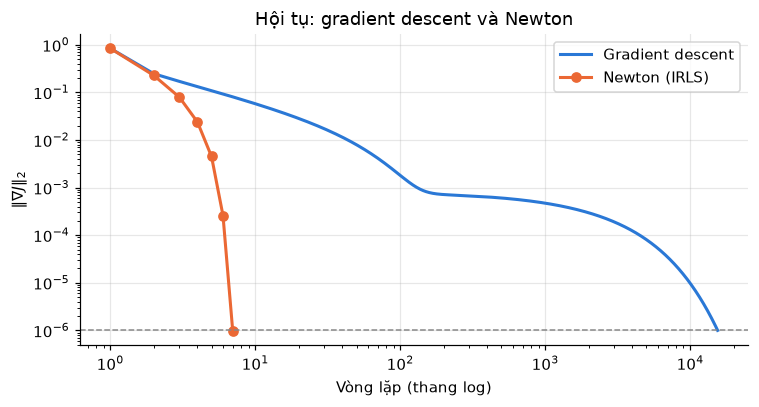

In [15]:
def hessian(X, w, b, lam):
    Xa = np.hstack([X, np.ones((len(X), 1))]); p = sigmoid(Xa @ np.r_[w, b])
    return (Xa * (p * (1 - p))[:, None]).T @ Xa / len(X) + np.diag(2 * lam * np.r_[np.ones(X.shape[1]), 0.0])

eig = np.linalg.eigvalsh(hessian(X_train, gd.w_, gd.b_, lam))
kappa = eig[-1] / eig[0]
nt = LogisticRegressionNewton(lam=lam, tol=TOL).fit(X_train, y_train)
print(f"Trị riêng Hessian tại nghiệm: nhỏ nhất {eig[0]:.2e}, lớn nhất {eig[-1]:.2e}; số điều kiện = {kappa:.0f}")
print(f"Newton hội tụ sau {nt.n_iter_} vòng; gradient descent cần {gd.n_iter_} vòng (cùng ngưỡng dừng)")
print(f"max |w_Newton - w_GD| = {np.max(np.abs(nt.w_ - gd.w_)):.2e}")
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.loglog(np.arange(1, len(gd.grad_norm_history_) + 1), gd.grad_norm_history_, color=C_NP, lw=2, label="Gradient descent")
ax.loglog(np.arange(1, len(nt.grad_norm_history_) + 1), nt.grad_norm_history_, color=C_SK, lw=2, marker="o", label="Newton (IRLS)")
ax.axhline(TOL, color=C_BASE, ls="--", lw=1)
ax.set_xlabel("Vòng lặp (thang log)"); ax.set_ylabel(r"$\|\nabla J\|_2$"); ax.set_title("Hội tụ: gradient descent và Newton"); ax.legend()
savefig("06_gd_vs_newton.png")
RESULTS["newton"] = {"n_iter": int(nt.n_iter_), "kappa": float(kappa),
                     "eig_min": float(eig[0]), "eig_max": float(eig[-1]),
                     "max_dw_vs_gd": float(np.max(np.abs(nt.w_ - gd.w_)))}

### 6.2. Gradient descent khi **không** chuẩn hoá đặc trưng

Cùng thuật toán, cùng quy tắc $\eta = 1/L_{\max}$, nhưng chạy trên dữ liệu gốc
(Area cỡ $10^4$, Extent cỡ $10^{-1}$).

Không chuẩn hoá: L_max = 8.337e+07, eta = 1.200e-08; sau 20000 vòng log loss train = 0.6681
Có chuẩn hoá   : eta = 0.8726; sau 15476 vòng log loss train = 0.1936
Accuracy Test của mô hình không chuẩn hoá sau 20000 vòng: 0.6706


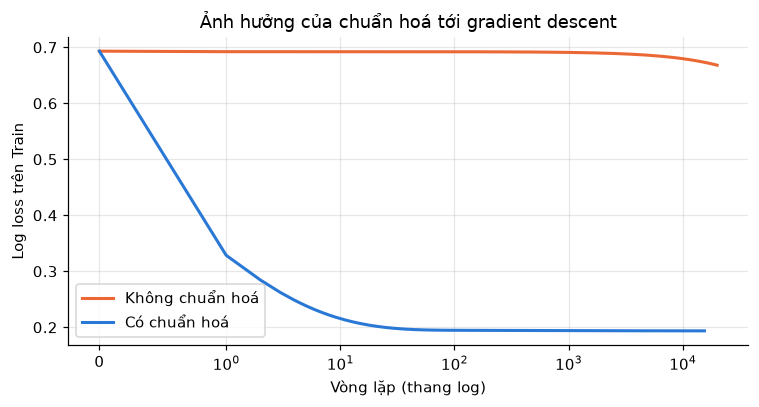

In [16]:
lam_raw = lam
L_raw = lipschitz_constant(X_train_raw, lam_raw)
gd_raw = LogisticRegressionGD(eta=1.0 / L_raw, lam=lam_raw, max_iter=20_000, tol=TOL).fit(X_train_raw, y_train)
k = gd_raw.n_iter_
print(f"Không chuẩn hoá: L_max = {L_raw:.3e}, eta = {1 / L_raw:.3e}; sau {k} vòng log loss train = {gd_raw.loss_history_[-1]:.4f}")
print(f"Có chuẩn hoá   : eta = {eta:.4f}; sau {min(k, gd.n_iter_)} vòng log loss train = {loss_hist[min(k, len(loss_hist) - 1)]:.4f}")
acc_raw = accuracy_score(y_test, (gd_raw.predict_proba(X_test_raw) >= 0.5).astype(int))
print(f"Accuracy Test của mô hình không chuẩn hoá sau {k} vòng: {acc_raw:.4f}")
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(gd_raw.loss_history_, color=C_SK, lw=2, label="Không chuẩn hoá")
ax.plot(loss_hist[:k + 1], color=C_NP, lw=2, label="Có chuẩn hoá")
ax.set_xscale("symlog", linthresh=1); ax.set_xlabel("Vòng lặp (thang log)"); ax.set_ylabel("Log loss trên Train")
ax.set_title("Ảnh hưởng của chuẩn hoá tới gradient descent"); ax.legend()
savefig("07_khong_chuan_hoa.png")
RESULTS["unscaled"] = {"L_max": L_raw, "eta": 1 / L_raw, "n_iter": int(k),
                       "train_log_loss": float(gd_raw.loss_history_[-1]),
                       "scaled_log_loss_same_iter": float(loss_hist[min(k, len(loss_hist) - 1)]),
                       "test_accuracy": float(acc_raw)}

### 6.3. Batch, mini-batch và SGD

Cùng số lượt duyệt dữ liệu (30 epoch). Trục hoành là số epoch để so công bằng.

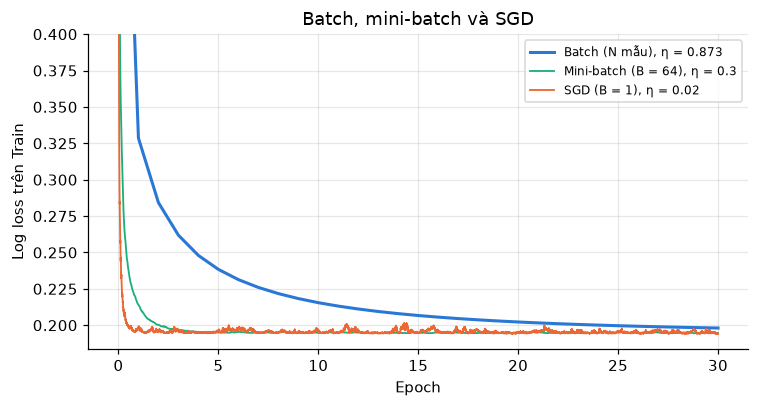

,Phương pháp,eta,số bước cập nhật,log loss train cuối,độ lệch chuẩn loss 2 epoch cuối
0,Batch (N mẫu),0.8726,30,0.1981,0.0001
1,Mini-batch (B = 64),0.3000,1071,0.1947,0.0002
2,SGD (B = 1),0.0200,68580,0.1942,0.0007


In [17]:
EPOCHS = 30
fig, ax = plt.subplots(figsize=(7, 3.8))
sgd_rows = []
for name, bs, e_, col in (("Batch (N mẫu)", None, eta, C_NP), ("Mini-batch (B = 64)", 64, 0.3, "#1baf7a"), ("SGD (B = 1)", 1, 0.02, C_SK)):
    steps = EPOCHS if bs is None else EPOCHS * n_train // bs
    m = LogisticRegressionGD(eta=e_, lam=lam, max_iter=steps, tol=0.0, batch_size=bs, random_state=SEED).fit(X_train, y_train)
    h = np.array(m.loss_history_)
    ax.plot(np.linspace(0, EPOCHS, len(h)), h, color=col, lw=1.2 if bs else 2, label=f"{name}, η = {e_:.3g}")
    sgd_rows.append({"Phương pháp": name, "eta": e_, "số bước cập nhật": steps,
                     "log loss train cuối": h[-1], "độ lệch chuẩn loss 2 epoch cuối": h[-max(2, 2 * len(h) // EPOCHS):].std()})
ax.set_ylim(loss_hist[-1] * 0.95, 0.4); ax.set_xlabel("Epoch"); ax.set_ylabel("Log loss trên Train")
ax.set_title("Batch, mini-batch và SGD"); ax.legend(fontsize=8)
savefig("08_batch_sgd.png")
display(pd.DataFrame(sgd_rows)); RESULTS["sgd"] = sgd_rows

### 6.4. Chọn C bằng cross-validation

$C = 1$ ở trên là giá trị mặc định. Ở đây chọn $C$ bằng CV 5-fold phân tầng trên Train,
scaler nằm trong pipeline nên được fit lại ở mỗi fold. Tiêu chí: log loss.

In [18]:
pipe = Pipeline([("scale", StandardScaler()), ("lr", LogisticRegression(tol=1e-8, max_iter=10_000))])
grid = GridSearchCV(pipe, {"lr__C": [0.001, 0.01, 0.1, 1, 10, 100, 1000]}, scoring="neg_log_loss",
                    cv=StratifiedKFold(5, shuffle=True, random_state=SEED)).fit(X_train_raw, y_train)
cvr = pd.DataFrame({"C": grid.cv_results_["param_lr__C"], "CV log loss (mean)": -grid.cv_results_["mean_test_score"],
                    "SD giữa các fold": grid.cv_results_["std_test_score"]})
cvr["SE"] = cvr["SD giữa các fold"] / np.sqrt(5)
display(cvr)
C_best = float(grid.best_params_["lr__C"])
best_row = cvr.loc[cvr["CV log loss (mean)"].idxmin()]
one_se = cvr[cvr["CV log loss (mean)"] <= best_row["CV log loss (mean)"] + best_row["SE"]]["C"].min()
print(f"C có CV log loss thấp nhất: {C_best:g}; C nhỏ nhất (mô hình đơn giản nhất) trong phạm vi 1 SE: {one_se:g}")
m_best = evaluate(y_test, grid.predict_proba(X_test_raw)[:, 1])
print(f"Test với C = {C_best:g}: accuracy = {m_best['Accuracy']:.4f}, log loss = {m_best['Log loss']:.4f}"
      f" (C = 1: accuracy = {table.loc['sklearn LogisticRegression', 'Accuracy']:.4f}, log loss = {table.loc['sklearn LogisticRegression', 'Log loss']:.4f})")
RESULTS["cv_C"] = {"table": cvr.astype(float).to_dict(orient="records"), "C_best": C_best,
                   "C_one_se": float(one_se), "test_metrics_best": m_best}

,C,CV log loss (mean),SD giữa các fold,SE
0,0.0010,0.3580,0.0051,0.0023
1,0.0100,0.2237,0.0047,0.0021
2,0.1000,0.1974,0.0036,0.0016
3,1.0000,0.1958,0.0037,0.0017
4,10.0000,0.1935,0.0038,0.0017
5,100.0000,0.1917,0.0044,0.0020
6,1000.0000,0.1917,0.0048,0.0021


C có CV log loss thấp nhất: 100; C nhỏ nhất (mô hình đơn giản nhất) trong phạm vi 1 SE: 10
Test với C = 100: accuracy = 0.9304, log loss = 0.1700 (C = 1: accuracy = 0.9239, log loss = 0.1767)


### 6.5. Độ bất định của các chỉ số (bootstrap) và so sánh hai bản

Tập Test có vài trăm mẫu nên mỗi chỉ số có sai số lấy mẫu. Khoảng tin cậy 95% lấy từ
2.000 lần bootstrap trên Test. Hai bản được so bằng kiểm định McNemar trên các mẫu mà
chúng dự đoán khác nhau.

In [19]:
rng = np.random.default_rng(SEED)
boot = {k: [] for k in table.columns}
for _ in range(2000):
    idx = rng.integers(0, len(y_test), len(y_test))
    for k_, v in evaluate(y_test[idx], p_np_test[idx]).items():
        boot[k_].append(v)
ci = pd.DataFrame({"Giá trị": table.loc["NumPy (gradient descent)"],
                   "CI 95% dưới": {k_: np.percentile(v, 2.5) for k_, v in boot.items()},
                   "CI 95% trên": {k_: np.percentile(v, 97.5) for k_, v in boot.items()}})
display(ci)
n01 = int(np.sum((yhat_np == y_test) & (yhat_sk != y_test)))
n10 = int(np.sum((yhat_np != y_test) & (yhat_sk == y_test)))
if n01 + n10 == 0:
    print("McNemar: hai bản dự đoán giống nhau trên toàn bộ Test (0 cặp bất đồng) nên không có khác biệt để kiểm định.")
    p_mc = 1.0
else:
    p_mc = binomtest(n01, n01 + n10, 0.5).pvalue
    print(f"McNemar chính xác: NumPy đúng/sklearn sai = {n01}, ngược lại = {n10}, p = {p_mc:.3f}")
RESULTS["bootstrap_ci"] = ci.to_dict(orient="index"); RESULTS["mcnemar"] = {"n01": n01, "n10": n10, "p": float(p_mc)}

,Giá trị,CI 95% dưới,CI 95% trên
Accuracy,0.9239,0.9042,0.9423
Precision,0.8964,0.8610,0.9270
Recall,0.9294,0.8994,0.9559
F1,0.9127,0.8882,0.9344
ROC-AUC,0.9814,0.9738,0.9880
Log loss,0.1767,0.1476,0.2082


McNemar: hai bản dự đoán giống nhau trên toàn bộ Test (0 cặp bất đồng) nên không có khác biệt để kiểm định.


### 6.6. Chất lượng xác suất và ngưỡng quyết định

ROC-AUC đo khả năng xếp hạng; Brier score và log loss đo chất lượng xác suất. Ngưỡng
$\tau$ được quét trên **Validation** theo F1 rồi khoá lại trước khi áp dụng lên Test.

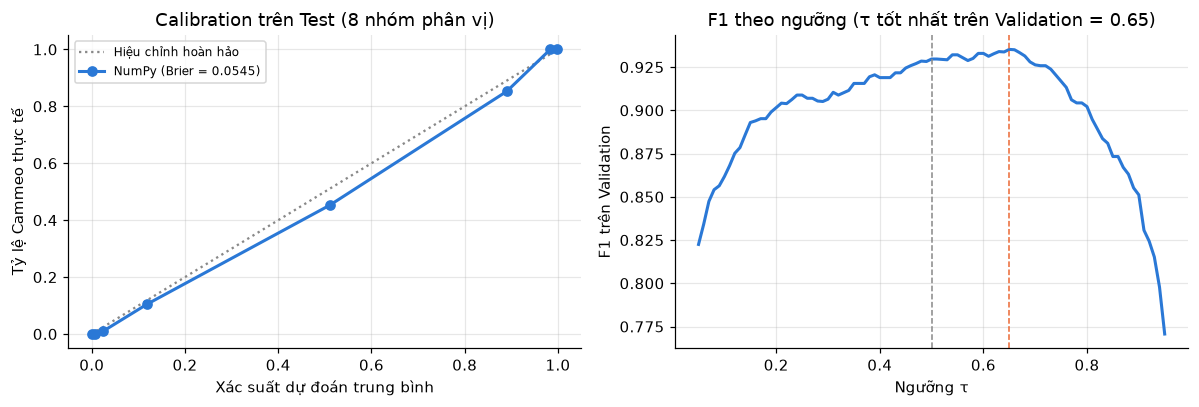

Brier score trên Test: 0.0545
F1 Validation: τ = 0,50 -> 0.9297; τ = 0.65 -> 0.9352
Test với τ = 0.65: accuracy = 0.9278, precision = 0.9385, recall = 0.8896, F1 = 0.9134


In [20]:
p_np_val = gd.predict_proba(X_val)
taus = np.linspace(0.05, 0.95, 91)
f1_val = [f1_score(y_val, (p_np_val >= t).astype(int)) for t in taus]
tau_best = float(taus[int(np.argmax(f1_val))])
frac_pos, mean_pred = calibration_curve(y_test, p_np_test, n_bins=8, strategy="quantile")
brier = brier_score_loss(y_test, p_np_test)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot([0, 1], [0, 1], color=C_BASE, ls=":", label="Hiệu chỉnh hoàn hảo")
axes[0].plot(mean_pred, frac_pos, color=C_NP, marker="o", lw=2, label=f"NumPy (Brier = {brier:.4f})")
axes[0].set_xlabel("Xác suất dự đoán trung bình"); axes[0].set_ylabel("Tỷ lệ Cammeo thực tế")
axes[0].set_title("Calibration trên Test (8 nhóm phân vị)"); axes[0].legend(fontsize=8)
axes[1].plot(taus, f1_val, color=C_NP, lw=2); axes[1].axvline(0.5, color=C_BASE, ls="--", lw=1)
axes[1].axvline(tau_best, color=C_SK, ls="--", lw=1)
axes[1].set_xlabel("Ngưỡng τ"); axes[1].set_ylabel("F1 trên Validation"); axes[1].set_title(f"F1 theo ngưỡng (τ tốt nhất trên Validation = {tau_best:.2f})")
savefig("09_calibration_nguong.png")
m_tau = evaluate(y_test, p_np_test, tau_best)
print(f"Brier score trên Test: {brier:.4f}")
print(f"F1 Validation: τ = 0,50 -> {f1_score(y_val, (p_np_val >= 0.5).astype(int)):.4f}; τ = {tau_best:.2f} -> {max(f1_val):.4f}")
print(f"Test với τ = {tau_best:.2f}: accuracy = {m_tau['Accuracy']:.4f}, precision = {m_tau['Precision']:.4f}, recall = {m_tau['Recall']:.4f}, F1 = {m_tau['F1']:.4f}")
RESULTS["calibration"] = {"brier": float(brier), "tau_best_val": tau_best,
                          "f1_val_at_05": float(f1_score(y_val, (p_np_val >= 0.5).astype(int))),
                          "f1_val_best": float(max(f1_val)), "test_at_tau_best": m_tau}

### 6.7. Đọc hệ số: odds ratio

Với đặc trưng đã chuẩn hoá, $\mathrm{OR}_j = e^{w_j}$ là hệ số nhân của odds(Cammeo) khi
đặc trưng $j$ tăng một độ lệch chuẩn, các đặc trưng khác giữ nguyên.

In [21]:
orr = pd.DataFrame({"w (NumPy)": gd.w_, "odds ratio exp(w)": np.exp(gd.w_)}, index=FEATURES)
orr["VIF"] = np.diag(np.linalg.inv(np.corrcoef(X_train, rowvar=False)))
display(orr.sort_values("w (NumPy)", key=np.abs, ascending=False))
RESULTS["odds_ratio"] = orr.to_dict(orient="index")

,w (NumPy),odds ratio exp(w),VIF
Convex_Area,2.0287,7.6044,1030.3492
Eccentricity,1.4126,4.1066,46.5841
Major_Axis_Length,0.9371,2.5525,366.1348
Area,0.4783,1.6133,1186.9047
Perimeter,0.4365,1.5472,232.5967
Minor_Axis_Length,-0.2578,0.7728,171.6733
Extent,0.0456,1.0466,1.1484


### 6.8. Tóm tắt phần mở rộng

- **Newton và số điều kiện (6.1):** Hessian tại nghiệm có số điều kiện khoảng 231. Newton
  hội tụ sau 6 vòng, gradient descent cần 15.476 vòng với cùng ngưỡng dừng. Độ cong thật
  lớn nhất là 0,106, nhỏ hơn nhiều so với cận $L_{\max} = 1{,}146$; vì thế $\eta = 1/L_{\max}$ an
  toàn nhưng dè dặt, và $\eta$ tới khoảng $2/0{,}106 \approx 19$ vẫn chưa phân kỳ (khớp với 2.3).
- **Không chuẩn hoá (6.2):** $L_{\max}$ tăng lên $8 \times 10^{7}$ nên bước học an toàn chỉ còn
  $1{,}2 \times 10^{-8}$; sau 20.000 vòng log loss mới giảm tới 0,668 và accuracy Test là 0,671,
  trong khi bản có chuẩn hoá đã hội tụ ở 0,194.
- **Batch, mini-batch, SGD (6.3):** với cùng 30 epoch, mini-batch và SGD xuống gần nghiệm
  nhanh hơn nhiều theo số lượt duyệt dữ liệu, đổi lại đường loss của SGD dao động quanh
  nghiệm thay vì giảm đều.
- **Chọn C (6.4):** CV log loss giảm dần khi C tăng và đi ngang từ C = 100 (0,1917). Theo
  quy tắc một sai số chuẩn, C = 10 là mô hình đơn giản nhất còn nằm trong phạm vi 1 SE.
  Trên Test, C = 100 cho accuracy 0,9304 và log loss 0,1700, so với 0,9239 và 0,1767 của
  C = 1: mức cải thiện nhỏ hơn bề rộng khoảng tin cậy ở 6.5.
- **Độ bất định (6.5):** accuracy 0,924 có khoảng tin cậy 95% là [0,904; 0,942]. Hai bản
  không có cặp dự đoán bất đồng nào nên không có khác biệt để kiểm định.
- **Xác suất và ngưỡng (6.6):** Brier score 0,0545. Ngưỡng tốt nhất theo F1 trên
  Validation là 0,65, nhưng trên Test F1 chỉ đổi từ 0,9127 lên 0,9134 (precision tăng,
  recall giảm), nên giữ $\tau = 0{,}5$ là hợp lý khi hai loại lỗi có chi phí như nhau.
- **Hệ số (6.7):** VIF của Area và Convex_Area trên 1.000, nên odds ratio của từng đặc
  trưng kích thước riêng lẻ không ổn định và không nên diễn giải tách rời; Extent gần như
  không đóng góp ($e^{w} \approx 1{,}05$).

In [22]:
(ROOT / "outputs" / "results.json").write_text(json.dumps(RESULTS, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
print("Đã lưu outputs/results.json và", len(list(FIG.glob("*.png"))), "hình trong outputs/figures/")

Đã lưu outputs/results.json và 9 hình trong outputs/figures/
